# 02 — Baseline Modeling: Predicta

## Objective

Build a first machine-learning model to estimate the Remaining Useful Life (RUL) of an engine using sensor measurements and operating settings.

## Dataset

NASA C-MAPSS Turbofan Engine Degradation Simulation Dataset — FD001.

## Approach

1. Load and prepare the dataset.
2. Split engines into training and validation sets.
3. Train a baseline regression model.
4. Evaluate predictions using MAE, RMSE, and R².
5. Document limitations and potential improvements.

## Experimental principle

All observations from a given engine must remain in the same split to reduce information leakage between training and validation data.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
PROJECT_ROOT = Path.cwd()

# Handle cases where PyCharm starts in the notebooks directory
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "train_FD001.txt"

columns = (
    ["unit", "cycle", "setting_1", "setting_2", "setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

train = pd.read_csv(
    DATA_PATH,
    sep=r"\s+",
    header=None,
    names=columns
)

last_cycle = train.groupby("unit")["cycle"].max()
train["RUL"] = train["unit"].map(last_cycle) - train["cycle"]

print("Dataset shape:", train.shape)
print("Number of engines:", train["unit"].nunique())
print("RUL range:", train["RUL"].min(), "to", train["RUL"].max())

train.head()

Dataset shape: (20631, 27)
Number of engines: 100
RUL range: 0 to 361


,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


In [3]:
engine_ids = train["unit"].unique()

train_units, val_units = train_test_split(
    engine_ids,
    test_size=0.2,
    random_state=42
)

train_df = train[train["unit"].isin(train_units)].copy()
val_df = train[train["unit"].isin(val_units)].copy()

print("Training engines:", train_df["unit"].nunique())
print("Validation engines:", val_df["unit"].nunique())
print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))

Training engines: 80
Validation engines: 20
Training rows: 16561
Validation rows: 4070


In [4]:
feature_cols = [
    col for col in train.columns
    if col.startswith("sensor_") or col.startswith("setting_")
]

X_train = train_df[feature_cols]
y_train = train_df["RUL"]

X_val = val_df[feature_cols]
y_val = val_df["RUL"]

print("Number of features:", len(feature_cols))
print("Training input shape:", X_train.shape)
print("Validation input shape:", X_val.shape)

Number of features: 24
Training input shape: (16561, 24)
Validation input shape: (4070, 24)


In [5]:
from sklearn.linear_model import Ridge

# Create the model
baseline_model = Ridge(alpha=1.0)

# Train it
baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [6]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Predict RUL for validation engines
y_pred = baseline_model.predict(X_val)

# Calculate evaluation metrics
mae = mean_absolute_error(y_val, y_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
r2 = r2_score(y_val, y_pred)

print(f"MAE:  {mae:.2f} cycles")
print(f"RMSE: {rmse:.2f} cycles")
print(f"R²:   {r2:.3f}")

MAE:  30.12 cycles
RMSE: 38.14 cycles
R²:   0.662


## Baseline Results — Ridge Regression

The initial Ridge Regression model was trained using 24 sensor and operating-setting features. Evaluation was performed on a validation set containing 20 engines that were excluded from training.

| Metric |       Result |
| ------ | -----------: |
| MAE    | 30.12 cycles |
| RMSE   | 38.14 cycles |
| R²     |        0.662 |

The model achieved an MAE of 30.12 cycles and an R² of 0.662 on the validation set. These results establish an initial reference point for subsequent experiments.

The RMSE was higher than the MAE, indicating that larger prediction errors contribute to the overall error. Further experiments will compare this baseline with simpler benchmarks and nonlinear models.

**Limitations:** This is a single engine-level validation split. The results may vary with a different split, and the model's performance should not be interpreted as evidence of deployment readiness.


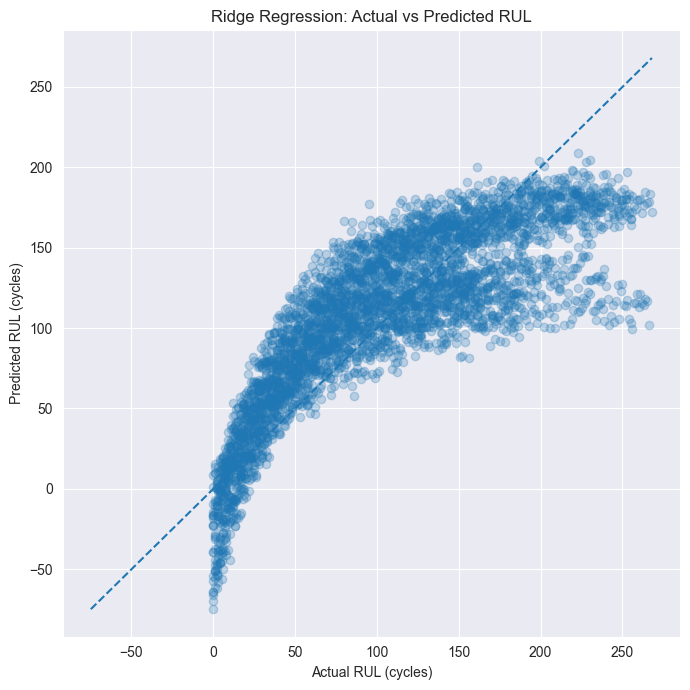

In [7]:
plt.figure(figsize=(7, 7))

plt.scatter(y_val, y_pred, alpha=0.25)

# Perfect predictions would lie on this diagonal
min_val = min(y_val.min(), y_pred.min())
max_val = max(y_val.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual RUL (cycles)")
plt.ylabel("Predicted RUL (cycles)")
plt.title("Ridge Regression: Actual vs Predicted RUL")
plt.tight_layout()
plt.show()

### Actual vs. Predicted RUL

The actual-versus-predicted plot shows a general positive relationship between actual and predicted RUL. However, predictions are compressed toward an intermediate range: the model tends to overestimate lower RUL values and underestimate higher RUL values.

The curved pattern suggests that a linear model may not fully capture the relationship between sensor measurements and RUL. This motivates testing a nonlinear regression model in a subsequent experiment.

These observations are based on visual inspection and should be confirmed with additional evaluation.
